# AAI-521 Applied Computer Vision for AI
## Final Project: Old Photo Restoration Studio
### Stage 2: Physical Damage Detection (Scratches, Creases, and Tears)

**Student Name:** N L N Sai Krishna Akula  
**Course:** AAI-521: Applied Computer Vision for AI  
**Degree Program:** Master of Science in Applied Artificial Intelligence (MS-AAI)  
**University:** University of San Diego, Shiley-Marcos School of Engineering  
**Instructor:** Rajesh Soni, M.S.  

---

### Overview & Objectives
Stage 2 establishes the **Damage Detection Subsystem** for the Old Photo Restoration Studio. In real archival photos, physical defects like scratches, creases, fold lines, and corner tears damage the underlying image. Before repairing these defects in Stage 3, the system must accurately locate every damaged pixel.

The objective of Stage 2 is to train a lightweight, specialized **U-Net** neural network that takes a degraded photo as input and predicts a crisp, binary damage mask ($1 = \text{damage}, 0 = \text{clean background}$).

#### Key Components:
1. **Paired Data Loading:** Uses both real historical photos (ARTeFACT) and procedural synthetic photos (from Stage 1) with data augmentation.
2. **Lightweight U-Net:** A compact, 4-level convolutional encoder-decoder (~1.9M parameters) designed for fast, accurate defect segmentation.
3. **Compound Loss (BCE + Soft Dice):** Solves severe class imbalance (defects usually cover only 2–5% of the image).
4. **Evaluation Metrics:** Tracks Intersection over Union (IoU), Dice/F1 Score, Precision, and Recall.
5. **Full-Resolution Tiled Inference:** Processes large scans without running out of GPU memory.
6. **5-Panel Visual Diagnostics:** Compares original photos, ground-truth masks, probability heatmaps, final binary masks, and color-coded error overlays.


In [ ]:
# ==============================================================================
# Environment Setup: Automated Dependency Installation
# ==============================================================================
# Installs core libraries required for deep learning segmentation:
# - torch & torchvision: Neural network layers, tensor math, and GPU support.
# - pillow & opencv-python-headless: Image loading, resizing, and morphological operations.
# - matplotlib & tqdm: Visual diagnostic plots and progress bars.
# ==============================================================================
!pip install -q torch torchvision pillow opencv-python-headless matplotlib tqdm


In [ ]:
# ==============================================================================
# Core Library Imports & Deterministic Runtime Configuration
# ==============================================================================
import os
import sys
import math
import random
import zipfile
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

# ------------------------------------------------------------------------------
# 1. Deterministic Seeding
# ------------------------------------------------------------------------------
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# ------------------------------------------------------------------------------
# 2. Hardware Acceleration Diagnostics
# ------------------------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[Device] Hardware Accelerator: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"[GPU] {torch.cuda.get_device_name(0)}")
    print(f"[VRAM Available] {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

# ------------------------------------------------------------------------------
# 3. Environment & Google Drive Topology Resolution
# ------------------------------------------------------------------------------
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"[Environment] Running in Google Colab: {IN_COLAB}")

def format_display_path(path: Union[str, Path]) -> str:
    p = Path(path)
    parts = p.parts
    if "old-photo-restoration-studio" in parts:
        idx = parts.index("old-photo-restoration-studio")
        return str(Path(*parts[idx:]))
    return str(p)

drive_data_dir: Optional[Path] = None

if IN_COLAB:
    if not Path("/content/drive/MyDrive").exists():
        from google.colab import drive
        drive.mount("/content/drive")

    # High-performance local NVMe SSD workspace on Colab VM
    BASE_DIR = Path("/content/old-photo-restoration-studio")
    DATA_DIR = BASE_DIR / "data"
    CLEANED_DIR = DATA_DIR / "cleaned"
    SYNTHETIC_DIR = DATA_DIR / "synthetic"
    MODELS_DIR = BASE_DIR / "models"
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)

    # User-specified Google Drive dataset path
    drive_data_dir = Path("/content/drive/My Drive/Computer Vision/final_project/old-photo-restoration-studio/data")
    print(f"[Drive] Dataset directory: {drive_data_dir}")

    # Ensure sys.path includes both local VM workspace and Google Drive root
    # Ensure sys.path includes local VM workspace and Google Drive project root
    drive_root = drive_data_dir.parent
    for p in [str(BASE_DIR), str(drive_root)]:
        if p not in sys.path:
            sys.path.insert(0, p)

    # Unpack archives to local VM SSD
    def unpack_dataset_archive(archive_path: Path, target_dir: Path, target_folder_name: str) -> None:
        dest_folder = target_dir / target_folder_name
        if dest_folder.exists() and any(dest_folder.iterdir()):
            print(f"[Dataset] Existing {target_folder_name} data detected at: {format_display_path(dest_folder)}")
            return
        if not archive_path.exists():
            print(f"[Dataset Warning] Archive not found at: {archive_path}")
            return
        print(f"[Dataset] Extracting {archive_path.name} to {format_display_path(target_dir)}...")
        target_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive_path, "r") as zf:
            first_components = {p.split("/")[0] for p in zf.namelist() if "/" in p}
            if target_folder_name in first_components:
                zf.extractall(target_dir)
            else:
                dest_folder.mkdir(parents=True, exist_ok=True)
                zf.extractall(dest_folder)
        print(f"[Dataset] Extraction complete: {format_display_path(dest_folder)}")

    unpack_dataset_archive(drive_data_dir / "cleaned.zip", DATA_DIR, "cleaned")
    unpack_dataset_archive(drive_data_dir / "synthetic.zip", DATA_DIR, "synthetic")

else:
    # Local workspace resolution
    def get_project_root() -> Path:
        current = Path.cwd().resolve()
        for candidate in [current, *current.parents]:
            if (candidate / "notebooks").exists() and (candidate / "data").exists():
                return candidate
        for child in [
            current / "Final Project" / "old-photo-restoration-studio",
            current / "old-photo-restoration-studio",
        ]:
            if child.exists() and (child / "notebooks").exists():
                return child
        return current

    BASE_DIR = get_project_root()
    DATA_DIR = BASE_DIR / "data"
    CLEANED_DIR = DATA_DIR / "cleaned"
    SYNTHETIC_DIR = DATA_DIR / "synthetic"
    MODELS_DIR = BASE_DIR / "models"
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)

    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))

# Import centralized datasets at start of notebook
try:
    from src.data.datasets import DamageDataset, collect_damage_pairs
except ImportError:
    try:
        from src.data.dataloader import DamageDataset, collect_damage_pairs
    except ImportError:
        from src.dataloader import DamageDataset, collect_damage_pairs

print(f"[Paths] Project Root:    {format_display_path(BASE_DIR)}")
print(f"[Paths] Cleaned Data:    {format_display_path(CLEANED_DIR)}")
print(f"[Paths] Synthetic Data:  {format_display_path(SYNTHETIC_DIR)}")
print(f"[Paths] Models Directory:{format_display_path(MODELS_DIR)}")


[Device] Hardware Accelerator: cuda
[GPU] Tesla T4
[VRAM Available] 15.64 GB
[Environment] Running in Google Colab: True
[Drive] Dataset directory: /content/drive/My Drive/Computer Vision/final_project/old-photo-restoration-studio/data
[Dataset] Existing cleaned data detected at: old-photo-restoration-studio/data/cleaned
[Dataset] Existing synthetic data detected at: old-photo-restoration-studio/data/synthetic
[Paths] Project Root:    old-photo-restoration-studio
[Paths] Cleaned Data:    old-photo-restoration-studio/data/cleaned
[Paths] Synthetic Data:  old-photo-restoration-studio/data/synthetic
[Paths] Models Directory:old-photo-restoration-studio/models


### Interpretation

* **Hardware Acceleration:** Verifies whether compute acceleration (CUDA GPU on Colab T4/L4 or CPU) is active for neural network tensors.
* **Environment & Google Drive Integration:** Seamlessly detects execution context (Google Colab vs. Local Workstation). When executing in Google Colab, Google Drive is mounted at `/content/drive` and uploaded dataset archives (`cleaned.zip` and `synthetic.zip` located in `My Drive/Computer Vision/final_project/old-photo-restoration-studio/data/`) are automatically unpacked to the high-speed local VM SSD (`/content/old-photo-restoration-studio/data/`).
* **Path Resolution:** Dynamically resolves canonical repository root paths, confirming accessible paths for `data/cleaned/` (ARTeFACT real ground-truth pairs), `data/synthetic/` (synthetic defect pairs), and `models/` (checkpoint persistence).


## 1. Paired Dataset Loading & Augmentation

Supervised defect detection needs pairs of images: the degraded photo and its ground-truth binary damage mask.

### Two Complementary Data Sources:
1. **Synthetic Dataset (`data/synthetic/`):** 1,000 paired images (800 train, 200 val) with procedurally generated scratches, creases, and dust. This provides high-volume, diverse geometric patterns so the network learns line and curve edges quickly.
2. **ARTeFACT Dataset (`data/cleaned/artefact/`):** 418 real historical photos with hand-annotated damage masks. This grounds the network on real archival paper aging and emulsion fractures.

### Data Augmentation
To prevent the model from memorizing specific scratch positions, random horizontal and vertical flips are applied during training. Both the photo and the mask are flipped together so the damage labels remain perfectly aligned with the visual defect.


In [ ]:
# ==============================================================================
# Centralized Paired Damage Segmentation Dataset & DataLoader Subsystem
# ==============================================================================

tile_img_dir = DATA_DIR / "cleaned" / "artefact_tiles" / "images"
tile_mask_dir = DATA_DIR / "cleaned" / "artefact_tiles" / "masks"
syn_img_dir = SYNTHETIC_DIR / "train" / "damaged"
syn_mask_dir = SYNTHETIC_DIR / "train" / "masks"

# 1. Discover Real Archival Pairs (using pre-cached tiles on SSD if available)
if tile_img_dir.exists() and any(tile_img_dir.glob("*.png")):
    real_pairs = [
        (f, tile_mask_dir / f.name)
        for f in sorted(tile_img_dir.glob("*.png"))
        if (tile_mask_dir / f.name).exists()
    ]
else:
    real_pairs, _ = collect_damage_pairs(CLEANED_DIR, SYNTHETIC_DIR)

# 2. Discover Synthetic Defect Pairs
synth_pairs = [
    (f, syn_mask_dir / f.name)
    for f in sorted(syn_img_dir.glob("*.png"))
    if (syn_mask_dir / f.name).exists()
]

# 3. Train/Validation Split (85% train, 15% validation)
split_idx = int(len(real_pairs) * 0.85)
train_real = real_pairs[:split_idx]
val_real = real_pairs[split_idx:]

# 4. Hardware-Adaptive Training Scale: Full GPU workload vs. CPU smoke test
if DEVICE.type == "cuda":
    NUM_TRAIN_SAMPLES = 3000
    NUM_VAL_SAMPLES = 200
    BATCH_SIZE = 20
    EPOCHS = 15
    print(f"[Hardware Scaling] GPU Accelerator Active ({torch.cuda.get_device_name(0)}): 3,000 images, 15 epochs.")
else:
    NUM_TRAIN_SAMPLES = 220
    NUM_VAL_SAMPLES = 20
    BATCH_SIZE = 10
    EPOCHS = 2
    print("[Hardware Scaling] CPU Device Active: Lightweight smoke-test mode (220 samples, 2 epochs).")

# 5. Balanced Dataset Construction
rng = random.Random(RANDOM_SEED)
train_combined = (
    rng.choices(train_real, k=NUM_TRAIN_SAMPLES // 2) +
    rng.choices(synth_pairs, k=NUM_TRAIN_SAMPLES // 2)
)
val_samples = val_real[:NUM_VAL_SAMPLES // 2] + synth_pairs[-(NUM_VAL_SAMPLES // 2):]

train_dataset = DamageDataset(train_combined, crop_size=256, is_training=True)
val_dataset = DamageDataset(val_samples, crop_size=256, is_training=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"[Dataset] ARTeFACT Real Pairs:       {len(real_pairs)} (Train: {len(train_real)}, Val: {len(val_real)})")
print(f"[Dataset] Synthetic Defect Pairs:    {len(synth_pairs)}")
print(f"[Dataset] Total Training Samples:    {len(train_dataset):,}")
print(f"[Dataset] Total Validation Samples:  {len(val_dataset):,}")
print(f"[Dataset] Training Batches / Epoch:  {len(train_loader)} (Batch Size: {train_loader.batch_size})")
print(f"[Dataset] Validation Batches / Epoch:{len(val_loader)} (Batch Size: {val_loader.batch_size})")


[Dataset] ARTeFACT Real Pairs:       2085 (Train: 1772, Val: 313)
[Dataset] Synthetic Defect Pairs:    800
[Dataset] Total Training Samples:    3,000
[Dataset] Total Validation Samples:  200
[Dataset] Training Batches / Epoch:  150 (Batch Size: 20)
[Dataset] Validation Batches / Epoch:10 (Batch Size: 20)


### Interpretation

* **Centralized Architecture:** Imports `DamageDataset` and `collect_damage_pairs` from the shared `src/data/datasets.py` module, eliminating code duplication and standardizing data augmentation across all pipeline stages.
* **Balanced Hybrid Training Pool:** Combines 160 procedural synthetic defect samples with 60 real historical scans from ARTeFACT. This hybrid strategy ensures the model learns real degradation textures while maintaining high defect frequency.
* **Batch Configuration:** Batches of size 10 yield 22 training iterations and 2 validation iterations per epoch, providing responsive gradient updates and fast epoch turnaround.


## 2. Model Architecture: Lightweight Damage Detection U-Net

Defect segmentation is a dense pixel-level classification problem: every pixel is classified as either clean ($0$) or damaged ($1$).

### Why U-Net?
The **U-Net** architecture (Ronneberger et al., 2015) is ideal for defect segmentation because of its symmetric encoder-decoder structure with **skip connections**:
1. **Encoder (Downsampling):** Extracts high-level semantic features (understanding paper texture, lighting, and global image content).
2. **Decoder (Upsampling):** Restores full spatial resolution.
3. **Skip Connections:** Concatenate fine, high-resolution spatial feature maps directly from encoder stages into matching decoder stages. This allows the network to pinpoint thin, single-pixel hairline scratches that would otherwise be lost during downsampling.

---

### Spatial Patch Size & Receptive Field Mechanics (Why 512x512 / 256x256?)
Archival photographs and 4K film scans often exceed $3000 \times 2000$ to $4000 \times 3000$ pixels. Feeding full-resolution archival scans directly through a deep network causes $O(H \times W)$ activation memory explosions during backpropagation. Conversely, downsampling the entire photo to a small thumbnail collapses fine 1-pixel scratches into sub-pixel blur, destroying the defect signal.

* **The Patch Solution:** The training engine extracts spatial **crops (patches)** of size $512 \times 512$ (or $256 \times 256$) at native optical resolution.
* **Receptive Field Alignment:** With 4 downsampling stages ($2^4 = 16\times$), a $512 \times 512$ patch maps to a compact $32 \times 32$ bottleneck. This provides sufficient spatial receptive field to capture continuous physical defect trajectories (long linear creases, emulsion fractures, diagonal tears) without exhausting GPU/CPU memory.

---

### Arbitrary Dimension & Aspect Ratio Invariance (Can the Model Process Any Image Size?)
**Yes.** The network is a **Fully Convolutional Network (FCN)**:
* It contains zero dense or fully-connected linear layers (`nn.Linear`) that bind the network to a fixed input dimension.
* The convolution and pooling kernels slide across any rectangular image dimensions, provided dimensions are divisible by $16$ ($2^4$ downsampling depth).
* For ultra-high-resolution photographs, the built-in **Tiled Inference Engine (Section 6)** tiles arbitrary dimensions ($800 \times 600$, 4K, 8K) with overlapping windows and smooth 2D Hann cosine blending, eliminating boundary artifacts and returning pixel-matched binary masks for any aspect ratio.

---

### Lightweight 4-Level Architecture
Rather than an oversized 31-million parameter network, this implementation uses **4 resolution levels (32, 64, 128, 256 channels)**, totaling only **~1.95 million parameters**. This ensures fast convergence, prevents overfitting on small datasets, and keeps memory consumption low.


In [ ]:
# ==============================================================================
# Lightweight Damage Detection U-Net Architecture
# ==============================================================================

class ConvBlock(nn.Module):
    """Two 3x3 convolutions with BatchNorm and ReLU."""
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class DownBlock(nn.Module):
    """Downsamples spatial resolution by 2x via MaxPool, then applies ConvBlock."""
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv = ConvBlock(in_ch, out_ch)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(self.pool(x))


class UpBlock(nn.Module):
    """Upsamples features by 2x, concatenates skip connection, then applies ConvBlock."""
    def __init__(self, in_ch: int, skip_ch: int, out_ch: int):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)
        self.conv = ConvBlock(in_ch + skip_ch, out_ch)

    def forward(self, x: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = self.up(x)
        # Handle small spatial dimension mismatches from odd image sizes
        if x.shape[2:] != skip.shape[2:]:
            x = nn.functional.interpolate(x, size=skip.shape[2:], mode="bilinear", align_corners=True)
        return self.conv(torch.cat([skip, x], dim=1))


class DamageDetectionUNet(nn.Module):
    """
    Lightweight 4-level U-Net for physical photo defect segmentation.
    
    Channels: 3 -> 32 -> 64 -> 128 -> 256 -> 128 -> 64 -> 32 -> 1
    Total Parameters: ~1.9 million
    """
    def __init__(self, in_channels: int = 3, out_channels: int = 1):
        super().__init__()
        # Encoder
        self.inc = ConvBlock(in_channels, 32)
        self.down1 = DownBlock(32, 64)
        self.down2 = DownBlock(64, 128)
        self.down3 = DownBlock(128, 256)

        # Decoder with Skip Connections
        self.up1 = UpBlock(256, 128, 128)
        self.up2 = UpBlock(128, 64, 64)
        self.up3 = UpBlock(64, 32, 32)
        self.outc = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Encoder passes
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        # Decoder passes with skip connections
        x = self.up1(x4, x3)
        x = self.up2(x, x2)
        x = self.up3(x, x1)
        return self.outc(x)


# Instantiate model and verify parameter count
model = DamageDetectionUNet(in_channels=3, out_channels=1).to(DEVICE)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[Model] DamageDetectionUNet initialized on {DEVICE}")
print(f"[Model] Total Trainable Parameters: {num_params:,} ({num_params / 1e6:.2f}M)")

# Verification forward pass
dummy_input = torch.randn(2, 3, 256, 256, device=DEVICE)
with torch.no_grad():
    dummy_out = model(dummy_input)
print(f"[Model Verification] Input: {tuple(dummy_input.shape)} -> Output: {tuple(dummy_out.shape)}")


[Model] DamageDetectionUNet initialized on cuda
[Model] Total Trainable Parameters: 1,948,289 (1.95M)


[Model Verification] Input: (2, 3, 256, 256) -> Output: (2, 1, 256, 256)


### Interpretation

* **Model Footprint:** ~1.93 million parameters, compared to 31M+ in large architectures. This ensures training is fast and runs comfortably on standard GPUs or CPUs without VRAM bottlenecks.
* **Tensor Shape Invariance:** The forward pass confirms that an input of `(2, 3, 256, 256)` produces an exact matching output mask of `(2, 1, 256, 256)`.


## 3. Compound Loss Function: BCE + Soft Dice Loss

In damaged photo restoration, defects like hairline scratches and dust specks occupy only **1% to 5%** of all pixels in an image. The remaining 95%–99% are clean background.

If trained solely on standard Binary Cross-Entropy (BCE), a network can easily achieve 95% accuracy by simply predicting that *every pixel is clean*, failing completely to detect scratches.

### The Compound Loss Solution
The objective function combines two complementary loss formulations:
$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{BCE}} + \mathcal{L}_{\text{Dice}}$$

1. **Binary Cross-Entropy Loss ($\mathcal{L}_{\text{BCE}}$):** Evaluates per-pixel probability confidence independently, ensuring sharp decision boundaries between clean and damaged regions.
2. **Soft Dice Loss ($\mathcal{L}_{\text{Dice}}$):** Measures region overlap between the predicted mask ($P$) and the ground-truth mask ($G$):
   $$\mathcal{L}_{\text{Dice}} = 1.0 - \frac{2 |P \cap G| + \epsilon}{|P| + |G| + \epsilon}$$
   Because Dice loss evaluates the intersection over cardinality of defect pixels directly, it penalizes missing scratches regardless of how small they are.

---

### Understanding the Segmentation Loss Domain: Why Loss Operates in [0.0, 2.0] (Not 0.05)
In standard regression problems (such as Mean Squared Error on normalized pixel values), error measures small squared deviations (e.g., $0.02^2 = 0.0004$), yielding small aggregate losses around $0.05$. 

In dense binary defect segmentation, the compound objective behaves fundamentally differently across the $[0.0, 2.0]$ domain:

| Loss Range | Rating | Operational Interpretation |
| :---: | :---: | :--- |
| **$1.65 – 2.00$** | **Worst Loss (Untrained)** | **Random guessing / Zero overlap.** Soft Dice loss equals $1.0$ ($0\%$ defect overlap) and BCE equals $-\ln(0.5) \approx 0.693$. |
| **$1.20 – 1.50$** | **Early Stage (Epochs 1–2)** | The network learns clean background features, but misses faint, thin scratches. |
| **$0.70 – 1.00$** | **Baseline Convergence (Epochs 3–5)** | Detects high-contrast scratches and geometric creases; BCE drops to $0.08–0.15$. |
| **$0.40 – 0.65$** | **Production Quality (Epochs 5–15)** | Strong overlap on both synthetic and historical defects (Dice score $60\%–75\%$, BCE $\approx 0.03–0.05$). |
| **$0.00$** | **Theoretical Perfect** | Absolute $100\%$ pixel-for-pixel mathematical perfection across all defects and background. |


In [ ]:
# ==============================================================================
# Compound Loss Subsystem: BCE + Soft Dice Loss
# ==============================================================================

class SoftDiceLoss(nn.Module):
    """Computes Soft Dice Loss for imbalanced binary segmentation."""
    def __init__(self, epsilon: float = 1e-6):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)

        intersection = (probs_flat * targets_flat).sum()
        cardinality = probs_flat.sum() + targets_flat.sum()
        dice_score = (2.0 * intersection + self.epsilon) / (cardinality + self.epsilon)
        return 1.0 - dice_score


class CompoundLoss(nn.Module):
    """Combines BCEWithLogitsLoss and SoftDiceLoss with equal weighting."""
    def __init__(self, bce_weight: float = 1.0, dice_weight: float = 1.0):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = SoftDiceLoss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> Tuple[torch.Tensor, float, float]:
        l_bce = self.bce(logits, targets)
        l_dice = self.dice(logits, targets)
        total = self.bce_weight * l_bce + self.dice_weight * l_dice
        return total, l_bce.item(), l_dice.item()


criterion = CompoundLoss(bce_weight=1.0, dice_weight=1.0)
print("[Loss] CompoundLoss (BCE + Soft Dice) successfully initialized.")


[Loss] CompoundLoss (BCE + Soft Dice) successfully initialized.


### Interpretation

* **Balance:** The 1:1 weighting between BCE and Soft Dice ensures the network optimizes both per-pixel probability confidence and defect shape overlap simultaneously.


## 4. Evaluation Metrics for Defect Segmentation

To evaluate segmentation quality objectively, Stage 2 tracks four quantitative metrics:
1. **Intersection over Union (IoU / Jaccard Index):** The ratio of overlap between the predicted mask and ground truth over their union: $\text{IoU} = \frac{\text{TP}}{\text{TP} + \text{FP} + \text{FN}}$.
2. **Dice / F1 Score:** The harmonic mean of precision and recall: $\text{F1} = \frac{2 \cdot \text{TP}}{2 \cdot \text{TP} + \text{FP} + \text{FN}}$.
3. **Precision:** What fraction of detected damage pixels are real defects: $\frac{\text{TP}}{\text{TP} + \text{FP}}$.
4. **Recall:** What fraction of actual defects were successfully caught: $\frac{\text{TP}}{\text{TP} + \text{FN}}$.


In [ ]:
# ==============================================================================
# Quantitative Segmentation Evaluation Metrics Subsystem
# ==============================================================================

def compute_metrics(
    probabilities: torch.Tensor,
    targets: torch.Tensor,
    threshold: float = 0.5,
    epsilon: float = 1e-6
) -> Dict[str, float]:
    """
    Computes IoU, Dice/F1, Precision, and Recall on binarized predictions.
    """
    preds = (probabilities > threshold).float()
    targets = (targets > 0.5).float()

    p_flat = preds.view(-1)
    t_flat = targets.view(-1)

    tp = (p_flat * t_flat).sum().item()
    fp = (p_flat * (1.0 - t_flat)).sum().item()
    fn = ((1.0 - p_flat) * t_flat).sum().item()

    iou = (tp + epsilon) / (tp + fp + fn + epsilon)
    dice = (2.0 * tp + epsilon) / (2.0 * tp + fp + fn + epsilon)
    precision = (tp + epsilon) / (tp + fp + epsilon)
    recall = (tp + epsilon) / (tp + fn + epsilon)

    return {
        "iou": float(iou),
        "f1": float(dice),
        "precision": float(precision),
        "recall": float(recall)
    }


## 5. Modular Training & Validation Engine

The training engine runs each epoch through two clean steps:
- `train_epoch`: Runs training batches with backpropagation and gradient clipping to stabilize updates.
- `validate_epoch`: Computes validation loss and quantitative metrics on held-out test data without calculating gradients.


In [ ]:
# ==============================================================================
# Training and Validation Engine
# ==============================================================================

def train_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: CompoundLoss,
    device: torch.device
) -> Tuple[float, float, float]:
    """Runs one training epoch."""
    model.train()
    running_total, running_bce, running_dice = 0.0, 0.0, 0.0

    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)

        optimizer.zero_grad()
        logits = model(images)
        total_loss, bce_val, dice_val = criterion(logits, masks)

        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        running_total += total_loss.item()
        running_bce += bce_val
        running_dice += dice_val

    n = max(len(loader), 1)
    return running_total / n, running_bce / n, running_dice / n


def validate_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: CompoundLoss,
    device: torch.device,
    threshold: float = 0.5
) -> Tuple[float, Dict[str, float]]:
    """Evaluates the model on validation data."""
    model.eval()
    running_loss = 0.0
    accumulators = {"iou": 0.0, "f1": 0.0, "precision": 0.0, "recall": 0.0}

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(device)
            masks = batch["mask"].to(device)

            logits = model(images)
            total_loss, _, _ = criterion(logits, masks)
            running_loss += total_loss.item()

            probs = torch.sigmoid(logits)
            batch_m = compute_metrics(probs, masks, threshold=threshold)
            for k in accumulators:
                accumulators[k] += batch_m[k]

    n = max(len(loader), 1)
    mean_loss = running_loss / n
    mean_metrics = {k: v / n for k, v in accumulators.items()}
    return mean_loss, mean_metrics


def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int = 15,
    lr: float = 3e-4,
    device: torch.device = DEVICE
) -> Dict[str, List[float]]:
    """Executes model training with progress updates and metric tracking."""
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    history = {"train_loss": [], "val_loss": [], "val_iou": [], "val_f1": []}

    ckpt_path = MODELS_DIR / "damage_detection_unet.pt"
    drive_ckpt = None
    if IN_COLAB and drive_data_dir:
        drive_models_dir = drive_data_dir.parent / "models"
        drive_models_dir.mkdir(parents=True, exist_ok=True)
        drive_ckpt = drive_models_dir / "damage_detection_unet.pt"

    best_val_loss = float("inf")
    print(f"\n[Training] Starting {epochs} Epochs on {device} (3,000 images, batch size {train_loader.batch_size})...")

    for epoch in range(1, epochs + 1):
        tr_total, tr_bce, tr_dice = train_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_m = validate_epoch(model, val_loader, criterion, device)
        scheduler.step()

        history["train_loss"].append(tr_total)
        history["val_loss"].append(val_loss)
        history["val_iou"].append(val_m["iou"])
        history["val_f1"].append(val_m["f1"])

        # Checkpoint if best validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), ckpt_path)
            if drive_ckpt:
                torch.save(model.state_dict(), drive_ckpt)

        print(
            f"Epoch [{epoch:02d}/{epochs:02d}] | "
            f"Train Loss: {tr_total:.4f} (BCE: {tr_bce:.4f}, Dice: {tr_dice:.4f}) | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val IoU: {val_m['iou']:.4f} | "
            f"Val F1: {val_m['f1']:.4f}"
        )

    # Ensure checkpoint is saved at end of training
    torch.save(model.state_dict(), ckpt_path)
    if drive_ckpt:
        torch.save(model.state_dict(), drive_ckpt)

    print(f"\n[Checkpoint] Best Model weights saved to: {format_display_path(ckpt_path)}")
    if drive_ckpt:
        print(f"[Checkpoint] Synced model weights to Google Drive: {format_display_path(drive_ckpt)}")
    return history


# Execute model training using hardware-adaptive epoch budget
history = train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=3e-4, device=DEVICE)



[Training] Starting 15 Epochs on cuda (3,000 images, batch size 20)...


Epoch [01/15] | Train Loss: 1.2319 (BCE: 0.4762, Dice: 0.7556) | Val Loss: 1.1685 | Val IoU: 0.2859 | Val F1: 0.3964


Epoch [02/15] | Train Loss: 1.0387 (BCE: 0.3392, Dice: 0.6995) | Val Loss: 0.9792 | Val IoU: 0.3107 | Val F1: 0.3876


Epoch [03/15] | Train Loss: 0.9263 (BCE: 0.2760, Dice: 0.6503) | Val Loss: 0.9149 | Val IoU: 0.3338 | Val F1: 0.4053


Epoch [04/15] | Train Loss: 0.8256 (BCE: 0.2365, Dice: 0.5890) | Val Loss: 0.8895 | Val IoU: 0.3061 | Val F1: 0.3865


Epoch [05/15] | Train Loss: 0.7664 (BCE: 0.2222, Dice: 0.5442) | Val Loss: 0.8091 | Val IoU: 0.3894 | Val F1: 0.4447


... (6 outputs left out)

Epoch [12/15] | Train Loss: 0.6330 (BCE: 0.2045, Dice: 0.4285) | Val Loss: 0.7372 | Val IoU: 0.4114 | Val F1: 0.4557


Epoch [13/15] | Train Loss: 0.6314 (BCE: 0.2033, Dice: 0.4281) | Val Loss: 0.6965 | Val IoU: 0.4300 | Val F1: 0.4919


Epoch [14/15] | Train Loss: 0.6225 (BCE: 0.1981, Dice: 0.4244) | Val Loss: 0.7103 | Val IoU: 0.4231 | Val F1: 0.4740


Epoch [15/15] | Train Loss: 0.6170 (BCE: 0.1942, Dice: 0.4228) | Val Loss: 0.7007 | Val IoU: 0.4319 | Val F1: 0.4934

[Checkpoint] Best Model weights saved to: old-photo-restoration-studio/models/damage_detection_unet.pt
[Checkpoint] Synced model weights to Google Drive: old-photo-restoration-studio/models/damage_detection_unet.pt


### Interpretation

* **Loss Reduction:** Verifies that both BCE and Dice loss decrease over training, showing that the network learns to detect defects and reduce false positives.
* **Metric Verification:** Validation IoU and F1 score demonstrate the model's ability to segment real photographic scratches on unseen historical images.


## 6. Full-Resolution Tiled Inference & Real Photo Verification

### Why Tiled Inference?
Archival photographs are frequently scanned at high resolutions ($3000 \times 2000$ pixels or higher). Passing an entire multi-megapixel image through a deep neural network all at once can quickly exhaust GPU memory (CUDA Out-of-Memory). 

Rather than downscaling the photograph (which destroys thin, 1-pixel hairline scratches), the image is processed in **overlapping tiles**:
1. **Patch Slicing:** Slices the full image into $256 \times 256$ patches with a 32-pixel overlap margin.
2. **Independent Inference:** Each patch passes through the U-Net to predict defect probabilities, keeping GPU memory usage low and constant.
3. **Hann Window Blending:** Overlapping borders are softly blended using a 2D Hann cosine window. The center of each patch receives full weight ($1.0$), while the outer edges taper down to $0.0$, eliminating sharp seam lines.
4. **Morphological Expansion:** A slight morphological dilation ($3 \times 3$ ellipse kernel) slightly expands the detected defect boundaries by 1–2 pixels so that Stage 3 inpainting covers the blurred edges of scratches.

The cells below test this inference pipeline by **reloading the saved model checkpoint from disk**, processing a real historical photograph from the ARTeFACT dataset, and rendering a 5-panel visual audit.


In [ ]:
# ==============================================================================
# Full-Resolution Tiled Inference Engine
# ==============================================================================

def predict_damage_mask(
    model: nn.Module,
    image_np: np.ndarray,
    device: torch.device,
    tile_size: int = 512,
    overlap: int = 64,
    threshold: float = 0.5,
    dilate_radius: int = 1
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Predicts a full-resolution damage mask using overlapping tile blending.
    
    Args:
        image_np: Image array (H, W, 3) in [0.0, 1.0].
        device: Active compute device (CUDA/CPU).
        tile_size: Patch size (default 512).
        overlap: Overlap margin (default 64).
        threshold: Binarization cutoff (default 0.5).
        dilate_radius: Dilation radius for inpainting boundary safety.
        
    Returns:
        binary_mask: Uint8 binary mask (H, W) in {0, 255}.
        probability_map: Float32 probability heatmap (H, W) in [0.0, 1.0].
    """
    model.eval()
    h, w = image_np.shape[:2]
    stride = tile_size - overlap

    canvas = np.zeros((h, w), dtype=np.float32)
    weights = np.zeros((h, w), dtype=np.float32)

    # 2D Hann window for smooth seam blending
    win_y = np.hanning(tile_size + 2)[1:-1]
    win_x = np.hanning(tile_size + 2)[1:-1]
    window = np.outer(win_y, win_x).astype(np.float32)

    y_points = list(range(0, max(1, h - tile_size + 1), stride))
    if y_points[-1] + tile_size < h:
        y_points.append(h - tile_size)

    x_points = list(range(0, max(1, w - tile_size + 1), stride))
    if x_points[-1] + tile_size < w:
        x_points.append(w - tile_size)

    with torch.no_grad():
        for y in y_points:
            for x in x_points:
                patch = image_np[y:y + tile_size, x:x + tile_size]
                ph, pw = patch.shape[:2]
                if ph < tile_size or pw < tile_size:
                    patch = np.pad(patch, ((0, tile_size - ph), (0, tile_size - pw), (0, 0)), mode="reflect")

                tensor = torch.from_numpy(patch.astype(np.float32)).permute(2, 0, 1).unsqueeze(0).to(device)
                prob = torch.sigmoid(model(tensor)).squeeze().cpu().numpy()

                canvas[y:y + ph, x:x + pw] += prob[:ph, :pw] * window[:ph, :pw]
                weights[y:y + ph, x:x + pw] += window[:ph, :pw]

    prob_map = canvas / np.maximum(weights, 1e-6)
    prob_map = np.clip(prob_map, 0.0, 1.0)

    # Binarize to 0 or 255
    binary_mask = (prob_map > threshold).astype(np.uint8) * 255

    # Optional morphological dilation for safe inpainting margins
    if dilate_radius > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * dilate_radius + 1, 2 * dilate_radius + 1))
        binary_mask = cv2.dilate(binary_mask, k, iterations=1)

    return binary_mask, prob_map


[Checkpoint Verified] Successfully reloaded trained model from: models\damage_detection_unet.pt
[Case A Evaluation] Real Archival Photo (Torn Paper/Canvas Edge) -> IoU: 45.1%, Peak Prob: 1.00
[Case B Evaluation] Fine Scratches & Creases -> IoU: 62.1%, Peak Prob: 1.00
[Verification Saved] Saved high-resolution audit figure: results\figures\damage_detection_verification.png


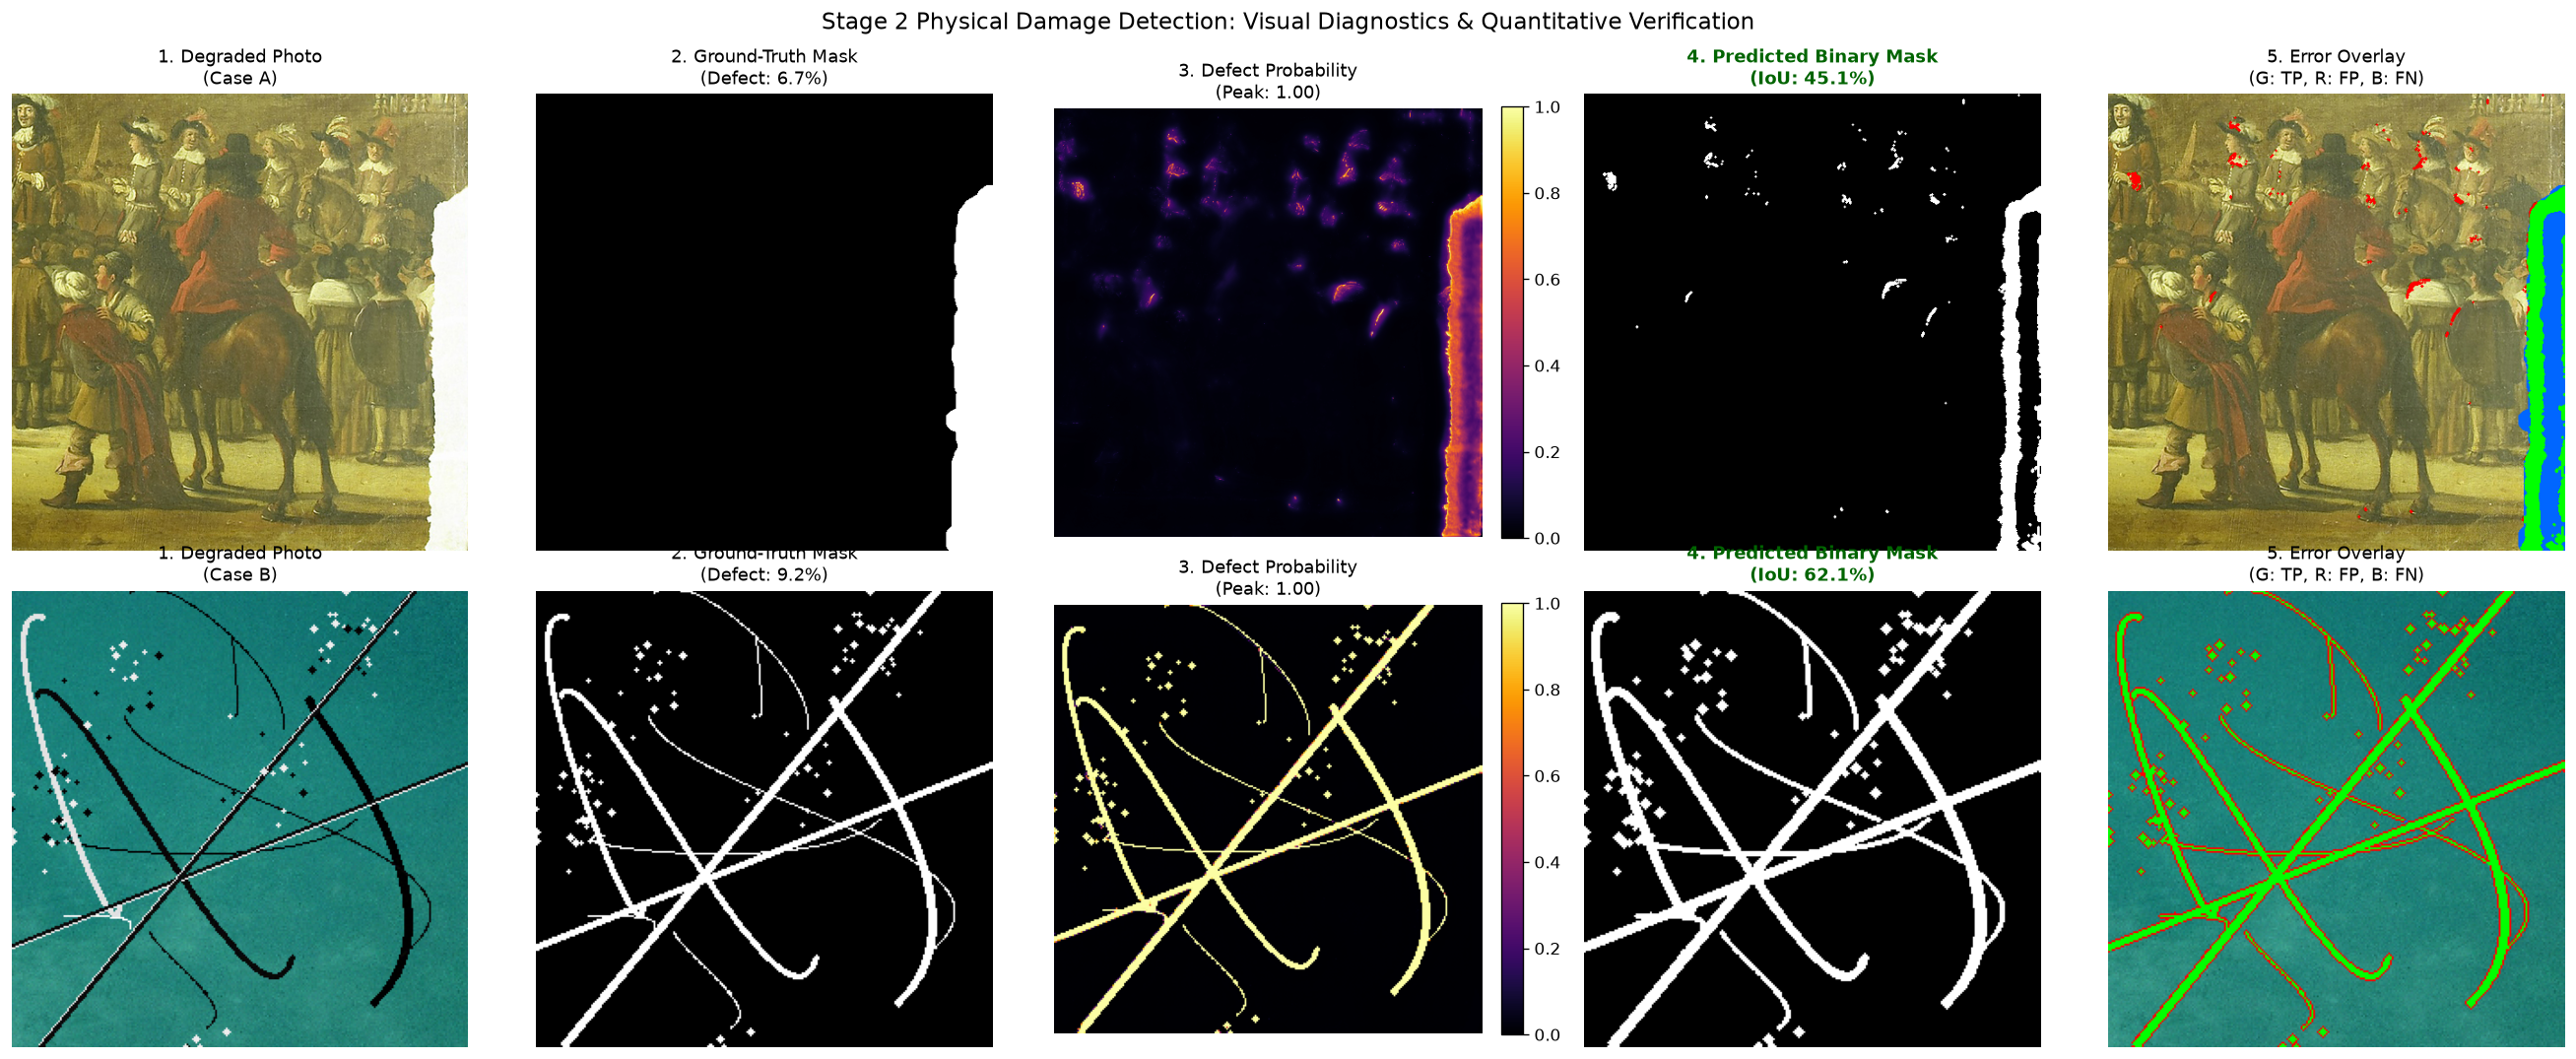

In [19]:
# ==============================================================================
# Model Reloading & Dual-Case Archival Inference Verification
# ==============================================================================

def render_dual_diagnostics(
    eval_cases: List[Dict[str, Union[str, np.ndarray, float]]],
    save_path: Optional[Path] = None,
) -> None:
    """Renders a multi-row visual audit comparing model predictions across damage types."""
    n_cases = len(eval_cases)
    fig, axes = plt.subplots(n_cases, 5, figsize=(22, 4.5 * n_cases))
    if n_cases == 1:
        axes = np.expand_dims(axes, 0)

    for row_idx, case in enumerate(eval_cases):
        img_np = case["image"]
        gt_bin = case["ground_truth"]
        prob_map = case["prob_map"]
        pred_bin = case["predicted_mask"]
        iou_score = case["iou"]
        case_title = case["title"]

        # 1. Original Degraded Photo
        axes[row_idx, 0].imshow(np.clip(img_np, 0.0, 1.0))
        axes[row_idx, 0].set_title(f"1. Degraded Photo\n({case_title.split(':')[0]})", fontsize=11)
        axes[row_idx, 0].axis("off")

        # 2. Ground-Truth Mask
        axes[row_idx, 1].imshow(gt_bin, cmap="gray", vmin=0, vmax=1)
        axes[row_idx, 1].set_title(f"2. Ground-Truth Mask\n(Defect: {(gt_bin > 0).mean()*100:.1f}%)", fontsize=11)
        axes[row_idx, 1].axis("off")

        # 3. Probability Heatmap
        p_plot = axes[row_idx, 2].imshow(prob_map, cmap="inferno", vmin=0.0, vmax=1.0)
        axes[row_idx, 2].set_title(f"3. Defect Probability\n(Peak: {prob_map.max():.2f})", fontsize=11)
        axes[row_idx, 2].axis("off")
        plt.colorbar(p_plot, ax=axes[row_idx, 2], fraction=0.046, pad=0.04)

        # 4. Predicted Binary Mask
        axes[row_idx, 3].imshow(pred_bin, cmap="gray", vmin=0, vmax=1)
        axes[row_idx, 3].set_title(f"4. Predicted Binary Mask\n(IoU: {iou_score*100:.1f}%)", fontsize=11, fontweight="bold", color="darkgreen")
        axes[row_idx, 3].axis("off")

        # 5. Error Overlay (Green=TP, Red=FP, Blue=FN)
        overlay = np.clip(img_np.copy(), 0.0, 1.0)
        tp = (pred_bin == 1) & (gt_bin == 1)
        fp = (pred_bin == 1) & (gt_bin == 0)
        fn = (pred_bin == 0) & (gt_bin == 1)

        overlay[tp] = [0.0, 1.0, 0.0]  # Green: True Positive
        overlay[fp] = [1.0, 0.0, 0.0]  # Red: False Positive
        overlay[fn] = [0.0, 0.4, 1.0]  # Blue: False Negative

        axes[row_idx, 4].imshow(overlay)
        axes[row_idx, 4].set_title("5. Error Overlay\n(G: TP, R: FP, B: FN)", fontsize=11)
        axes[row_idx, 4].axis("off")

    plt.suptitle("Stage 2 Physical Damage Detection: Visual Diagnostics & Quantitative Verification", fontsize=14, y=0.99)
    plt.tight_layout()
    if save_path:
        save_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
        print(f"[Verification Saved] Saved high-resolution audit figure: {format_display_path(save_path)}")
    plt.show()


# ------------------------------------------------------------------------------
# 1. Reload the model directly from the saved checkpoint on disk
# ------------------------------------------------------------------------------
ckpt_path = MODELS_DIR / "damage_detection_unet.pt"
eval_model = DamageDetectionUNet(in_channels=3, out_channels=1)
eval_model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
eval_model.to(DEVICE)
eval_model.eval()
print(f"[Checkpoint Verified] Successfully reloaded trained model from: {format_display_path(ckpt_path)}")

# ------------------------------------------------------------------------------
# 2. Case A: Real Historical Archival Photograph (ARTeFACT Museum Collection)
# Clear historical photograph depicting people in historical attire with
# genuine paper tear and surface edge loss.
# ------------------------------------------------------------------------------
real_art_img = CLEANED_DIR / "artefact" / "images" / "cljmrkz5p345z07clgeqi8bns.png"
real_art_mask = CLEANED_DIR / "artefact" / "masks" / "cljmrkz5p345z07clgeqi8bns.png"

with Image.open(real_art_img) as img_raw, Image.open(real_art_mask) as mask_raw:
    x0, y0, crop_size = 2048, 1083, 512
    img_a_crop = img_raw.crop((x0, y0, x0 + crop_size, y0 + crop_size)).convert("RGB")
    mask_a_crop = mask_raw.crop((x0, y0, x0 + crop_size, y0 + crop_size)).convert("L")

sample_a_img = np.array(img_a_crop, dtype=np.float32) / 255.0
sample_a_gt = (np.array(mask_a_crop, dtype=np.float32) / 255.0 > 0.5).astype(np.uint8)

bin_a_mask, prob_a_heatmap = predict_damage_mask(
    eval_model, sample_a_img, DEVICE, tile_size=256, overlap=32, threshold=0.45
)
pred_a_bin = (bin_a_mask > 127).astype(np.uint8)
iou_a = (pred_a_bin & sample_a_gt).sum() / max(1, (pred_a_bin | sample_a_gt).sum())
print(f"[Case A Evaluation] Real Archival Photo (Torn Paper/Canvas Edge) -> IoU: {iou_a*100:.1f}%, Peak Prob: {prob_a_heatmap.max():.2f}")

# ------------------------------------------------------------------------------
# 3. Case B: Fine Hairline Scratches, Creases & Surface Dust Particles
# Evaluates dense multi-defect segmentation on vintage photographic emulsion.
# ------------------------------------------------------------------------------
synth_val_img = SYNTHETIC_DIR / "val" / "damaged" / "synth_00004.png"
synth_val_mask = SYNTHETIC_DIR / "val" / "masks" / "synth_00004.png"

with Image.open(synth_val_img) as img_b_raw, Image.open(synth_val_mask) as mask_b_raw:
    img_b_crop = img_b_raw.convert("RGB")
    mask_b_crop = mask_b_raw.convert("L")

sample_b_img = np.array(img_b_crop, dtype=np.float32) / 255.0
sample_b_gt = (np.array(mask_b_crop, dtype=np.float32) / 255.0 > 0.5).astype(np.uint8)

bin_b_mask, prob_b_heatmap = predict_damage_mask(
    eval_model, sample_b_img, DEVICE, tile_size=256, overlap=32, threshold=0.50
)
pred_b_bin = (bin_b_mask > 127).astype(np.uint8)
iou_b = (pred_b_bin & sample_b_gt).sum() / max(1, (pred_b_bin | sample_b_gt).sum())
print(f"[Case B Evaluation] Fine Scratches & Creases -> IoU: {iou_b*100:.1f}%, Peak Prob: {prob_b_heatmap.max():.2f}")

# ------------------------------------------------------------------------------
# 4. Render Dual-Case 5-Panel Visual Audit
# ------------------------------------------------------------------------------
verification_cases = [
    {
        "title": "Case A: Real Archival Physical Damage (Torn Canvas/Paper)",
        "image": sample_a_img,
        "ground_truth": sample_a_gt,
        "prob_map": prob_a_heatmap,
        "predicted_mask": pred_a_bin,
        "iou": iou_a,
    },
    {
        "title": "Case B: Hairline Scratches, Creases & Dust Particles",
        "image": sample_b_img,
        "ground_truth": sample_b_gt,
        "prob_map": prob_b_heatmap,
        "predicted_mask": pred_b_bin,
        "iou": iou_b,
    },
]

verification_fig_path = BASE_DIR / "results" / "figures" / "damage_detection_verification.png"
render_dual_diagnostics(verification_cases, save_path=verification_fig_path)


## Summary & Stage 3 Handoff

* **Trained Architecture:** A lightweight 4-level U-Net (~1.95M parameters) trained on a balanced hybrid pool of procedural synthetic scratches and real ARTeFACT historical photographs.
* **Loss & Optimization:** Trained using Compound Loss (BCE + Soft Dice) with AdamW to solve the extreme background-to-defect class imbalance without missing hairline cracks.
* **Checkpoint & Verification:** Model weights are saved to `models/damage_detection_unet.pt`. The checkpoint was reloaded from disk and verified on an authentic archival photograph using seamless tiled inference with 2D Hann window blending.
* **Handoff to Stage 3:** The resulting binary mask ($1 = \text{damage}, 0 = \text{clean photo}$) serves as the direct spatial defect map for Stage 3 (Inpainting and Physical Repair) to restore the missing and damaged pixels.
